In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importing the ICLR OpenReview Dataset

In [2]:
# Master dataframe made by data/generate.py: every paper (2017-2025) without "Anonymous",
# with its SBERT embedding, last author, and outcome. It lives outside the repo.
iclr2025v2 = pd.read_parquet("../embeddings/master.parquet")

# Only 2021+: OpenReview author ids start in 2021, and they separate people who share a name
iclr2025v2 = iclr2025v2[iclr2025v2["year"] > 2020].reset_index(drop=True)
iclr2025v2.head()

,paper_idx,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels,n_authors,last_author,last_author_id,has_author_ids,decision_group,accepted,mean_score,embedding
0,5637,2021,--GJkm7nt0,Enhancing Visual Representations for Efficient...,"We propose ENVISE, an online distillation fra...","Shashanka Venkataramanan, Bruce W McIntosh, Ab...","~Shashanka_Venkataramanan1, ~Bruce_W_McIntosh1...",Reject,"[4, 5, 5, 4]",[],unlabeled,3,Abhijit Mahalanobis,~Abhijit_Mahalanobis1,True,reject,False,4.500000,"[-0.048169218, 0.06054135, -0.020331614, 0.128..."
1,5638,2021,--gvHfE3Xf5,Meta-Learning of Structured Task Distributions...,"In recent years, meta-learning, in which a mod...","Sreejan Kumar, Ishita Dasgupta, Jonathan Cohen...","~Sreejan_Kumar1, ~Ishita_Dasgupta1, ~Jonathan_...",Accept (Poster),"[6, 6, 7, 7]","[meta-learning, human cognition, reinforcement...",meta learning,5,Thomas Griffiths,~Thomas_Griffiths1,True,accept,True,6.500000,"[0.05333323, -0.0034514603, -0.05918646, -0.09..."
2,5639,2021,--rcOeCKRh,CROSS-SUPERVISED OBJECT DETECTION,After learning a new object category from imag...,"Zitian Chen, Zhiqiang Shen, Jiahui Yu, Erik Le...","~Zitian_Chen1, ~Zhiqiang_Shen1, ~Jiahui_Yu1, ~...",Reject,"[6, 4, 6, 6]","[object detection, weakly supervised, transfer...",object detection,4,Erik Learned-Miller,~Erik_Learned-Miller2,True,reject,False,5.500000,"[0.024875889, -0.031187244, 0.048517704, 0.132..."
3,5640,2021,-2FCwDKRREu,Learning Invariant Representations for Reinfor...,We study how representation learning can accel...,"Amy Zhang, Rowan Thomas McAllister, Roberto Ca...","~Amy_Zhang1, ~Rowan_Thomas_McAllister1, ~Rober...",Accept (Oral),"[7, 7, 9]","[rich observations, bisimulation metrics, repr...",unlabeled,5,Sergey Levine,~Sergey_Levine1,True,accept,True,7.666667,"[-0.102663144, 0.114053436, -0.030107262, 0.01..."
4,5641,2021,-5VpoDCExrU,Log representation as an interface for log pro...,"Log files are files that record events, messag...","Mohammad Amin Sadeghi, Shameem Parambath, Ji L...","~Mohammad_Amin_Sadeghi3, spparambath@hbku.edu....",Reject,"[7, 4, 5, 3]","[vector embedding, logs, search, causal analys...",anomaly detection,8,Sanjay Chawla,~Sanjay_Chawla2,True,reject,False,4.750000,"[-0.058153152, 0.12679349, -0.00436233, 0.0540..."


In [ ]:
np.unique()

# Paper Representation: Loading the SBERT Embeddings

The embeddings come from the master dataframe, so row `i` of the embeddings is row `i` of the dataframe above. We normalise them so that a dot product between two papers is their cosine similarity.

In [3]:
embedding_av = np.stack(iclr2025v2["embedding"])
print("Embedding shape:", embedding_av.shape)

embedding_av = embedding_av / np.linalg.norm(embedding_av, axis=1, keepdims=True)

Embedding shape: (30433, 768)


# Resubmissions

Note for the group: a paper rejected from ICLR is often resubmitted the next year with an almost identical abstract. Its pivot is then close to 0, because its own earlier version is part of the author's history, and its decision partly depends on the earlier rejection.

We treat two papers as versions of the same paper when they share an author, come from different years, and have a cosine similarity of at least 0.90. Above 0.90 the pairs we inspected were almost all resubmissions (often with the same title); below it they mix renamed resubmissions with follow-up papers, which we want to keep.

Rule: we keep only the latest version of each chain, and a chain ends at its first accepted version. Papers that come after an accepted version are follow-ups of a published paper (e.g. *GRAND++* accepted in 2022, then *DeepGRAND* in 2023), not resubmissions, so we keep them. The earlier versions are left out of the analysis and of the authors' histories.

In [4]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# Group paper indices by author (OpenReview id)
papers_by_author = {}

# dataframe, author -> paper indices
for idx, row in iclr2025v2.iterrows():
    for author in dict.fromkeys(a.strip() for a in row["author_ids"].split(",") if a.strip()):
        papers_by_author.setdefault(author, []).append(idx)

# Pairs of near-identical papers that share an author and come from different years
similarity_threshold = 0.90
paper_years = iclr2025v2["year"].to_numpy()
pairs = set()

for author, indices in papers_by_author.items():

    if len(indices) < 2:
        continue

    indices = np.array(indices)
    similarities = embedding_av[indices] @ embedding_av[indices].T
    rows, cols = np.where(np.triu(similarities >= similarity_threshold, k=1))

    for r, c in zip(rows, cols):
        if paper_years[indices[r]] != paper_years[indices[c]]:
            pairs.add((indices[r], indices[c]))

# Link the pairs into chains of versions (A -> B -> C)
pairs = np.array(sorted(pairs))
graph = coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(len(iclr2025v2), len(iclr2025v2)))
_, chain_id = connected_components(graph, directed=False)

resubmissions = iclr2025v2.assign(chain=chain_id, accepted=iclr2025v2["decision"].str.startswith("Accept"))
resubmissions = resubmissions[resubmissions.groupby("chain")["id"].transform("size") > 1]

# A chain ends at its first accepted version (or at its latest version if none was accepted);
# we keep that version and drop the earlier ones. Papers after an acceptance are follow-ups and stay.
first_accepted = resubmissions[resubmissions["accepted"]].groupby("chain")["year"].min()
end_year = resubmissions["chain"].map(first_accepted).fillna(resubmissions.groupby("chain")["year"].transform("max"))

resubmission_drop = set(resubmissions.index[resubmissions["year"] < end_year])
kept = resubmissions.index.difference(list(resubmission_drop))
follow_ups = resubmissions.index[resubmissions["year"] > end_year]

print(f"Chains of resubmitted papers: {resubmissions['chain'].nunique()}")
print(f"Chains with an accepted version: {resubmissions.groupby('chain')['accepted'].any().sum()}")
print(f"Follow-ups of an accepted paper (kept): {len(follow_ups)}")
print(f"Papers left out: {len(resubmission_drop)} of {len(iclr2025v2)}")

Chains of resubmitted papers: 433
Chains with an accepted version: 111
Follow-ups of an accepted paper (kept): 19
Papers left out: 430 of 30433


In [5]:
# A few chains, with the version we keep
resubmissions["kept"] = resubmissions.index.isin(kept)
sample_chains = resubmissions["chain"].drop_duplicates().sample(5, random_state=42)

resubmissions[resubmissions["chain"].isin(sample_chains)].sort_values(["chain", "year"])[["chain", "year", "decision", "kept", "title", "abstract"]]

,chain,year,decision,kept,title,abstract
1825,1825,2021,Accept (Poster),True,Fully Unsupervised Diversity Denoising with Co...,Deep Learning based methods have emerged as th...
3746,1825,2022,Accept (Spotlight),True,Interpretable Unsupervised Diversity Denoising...,Image denoising and artefact removal are compl...
3881,3871,2022,Reject,False,Understanding the Generalization of Adam in Le...,Adaptive gradient methods such as Adam have ga...
10028,3871,2023,Accept: poster,True,Understanding the Generalization of Adam in Le...,Adaptive gradient methods such as Adam have ga...
7940,7863,2023,Reject,False,DITTO: Offline Imitation Learning with World M...,"We propose DITTO, a fully offline approach to ..."
15747,7863,2024,Reject,True,DITTO: Offline Imitation Learning with World M...,For imitation learning algorithms to scale to ...
15420,15211,2024,Withdrawn,False,Learning Invariant Graph Representations via V...,Graph invariant learning aims to learn invaria...
24618,15211,2025,Accept (Poster),True,Learning Graph Invariance by Harnessing Spurio...,"Recently, graph invariant learning has become ..."
18510,18248,2024,Reject,False,Discrimination-free Pricing with Privatized Se...,Fairness has emerged as a critical considerati...
23740,18248,2025,Reject,True,Discrimination-free Insurance Pricing with Pri...,Fairness has emerged as a critical considerati...


# Pivot Index

We define the pivot index of a paper $j$ by author $a$ published in year $t$ as

$$\Phi_{aj} = 1 - \cos\left(e_j, \bar e_{H(a,t)}\right),$$

where $\bar e_{H(a,t)}$ is the mean embedding of all of the author's papers from years before $t$. The idea comes from Hill et al. (2025), but we measure prior work through abstract embeddings. A pivot close to 0 means the paper stays close to the author's prior work. Papers from the same year are not part of the history, and the pivot is undefined for an author's first year.

We also compute two alternatives that use the author's history differently:
- **Nearest prior paper:** $\Phi^{nn}_{aj} = 1 - \max_{i \in H(a,t)} \cos(e_j, e_i)$, how far the paper is from the most similar paper the author has written before.
- **Mean of the $k$ closest prior papers:** the same as $\Phi_{aj}$, but the mean embedding only uses the $k = 3$ earlier papers most similar to $e_j$. Since $k$ is below our threshold of 5 prior papers, every PI pivot of this kind is built from exactly 3 papers.

In [6]:
# Making the paper-author dataframe, one row per author of each paper
records = []

for idx, row in iclr2025v2.iterrows():

    # leave out the other versions of resubmitted papers
    if idx in resubmission_drop:
        continue

    # splitting list of authors, identified by their OpenReview id (e.g. ~Sergey_Levine1)
    paper_authors = list(dict.fromkeys(
        a.strip()
        for a in row["author_ids"].split(",")
        if a.strip()
    ))

    for position, author in enumerate(paper_authors):
        records.append({
            "paper_idx": idx,
            "paper_id": row["id"],
            "year": row["year"],
            "author": author,
            "is_last_author": position == len(paper_authors) - 1,
            "decision": row["decision"],
        })

author_papers = pd.DataFrame(records)
author_papers.head()

,paper_idx,paper_id,year,author,is_last_author,decision
0,0,--GJkm7nt0,2021,~Shashanka_Venkataramanan1,False,Reject
1,0,--GJkm7nt0,2021,~Bruce_W_McIntosh1,False,Reject
2,0,--GJkm7nt0,2021,~Abhijit_Mahalanobis1,True,Reject
3,1,--gvHfE3Xf5,2021,~Sreejan_Kumar1,False,Accept (Poster)
4,1,--gvHfE3Xf5,2021,~Ishita_Dasgupta1,False,Accept (Poster)


In [7]:
# For each paper of an author, compare it to the mean embedding of the author's earlier papers,
# to the nearest earlier paper, and to the mean embedding of the k closest earlier papers
k = 3
pivot_records = []

for author, group in author_papers.groupby("author"):

    # from the author-defined group:
    paper_indices = group["paper_idx"].to_numpy() # list of all paper indices
    years = group["year"].to_numpy() # list of all years

    for paper_idx, year in zip(paper_indices, years):

        prior_indices = paper_indices[years < year] # prior history

        if len(prior_indices) == 0:
            pivot = np.nan
            pivot_nn = np.nan
            pivot_k = np.nan
            nearest_prior_idx = -1
        else:

            # OG prior history vector
            prior_mean = embedding_av[prior_indices].mean(axis=0) # prior history vector
            prior_mean = prior_mean / np.linalg.norm(prior_mean) # normalized
            pivot = 1 - embedding_av[paper_idx] @ prior_mean

            # similarity of the present paper to EACH of the author's earlier papers
            similarities = embedding_av[prior_indices] @ embedding_av[paper_idx]

            # nearest prior paper
            pivot_nn = 1 - similarities.max()
            nearest_prior_idx = prior_indices[similarities.argmax()]

            # mean embedding of the k = 3 closest prior papers
            closest_indices = prior_indices[np.argsort(similarities)[-k:]]
            closest_mean = embedding_av[closest_indices].mean(axis=0)
            closest_mean = closest_mean / np.linalg.norm(closest_mean)


            
            pivot_k = 1 - embedding_av[paper_idx] @ closest_mean

        pivot_records.append({
            "paper_idx": paper_idx,
            "author": author,
            "n_prior": len(prior_indices),
            "pivot": pivot,
            "pivot_nn": pivot_nn,
            "pivot_k": pivot_k,
            "nearest_prior_idx": nearest_prior_idx,
        })

author_papers = author_papers.merge(pd.DataFrame(pivot_records), on=["paper_idx", "author"])


For each paper we keep the pivot of the last listed author (the PI), identified by their OpenReview id, as in our initial analysis. We only keep PIs with at least 5 papers in earlier years so that the mean of their prior work is meaningful. Since our data starts in 2021, the first pivots are in 2022.

In [8]:
threshold = 5

pi_pivot = author_papers[
    author_papers["is_last_author"] & (author_papers["n_prior"] >= threshold)
].copy()

pi_pivot = pi_pivot.merge(iclr2025v2[["id", "title"]], left_on="paper_id", right_on="id").drop(columns="id")

print(f"Papers with a PI pivot: {len(pi_pivot)} of {len(iclr2025v2)}")
pi_pivot["pivot"].describe()

Papers with a PI pivot: 8723 of 30433


count    8723.000000
mean        0.405958
std         0.117479
min         0.092857
25%         0.319976
50%         0.397463
75%         0.482479
max         0.922937
Name: pivot, dtype: float64

# Initial Analysis

Exploratory. Observe that the mean pivot index value is 0.4: it's common for researchers to include some topic pivoting in their publishing. Distribution is right skewed (makes sense, researchers tend to specialize). The proportion of researchers pivoting very high (0.6 <=) is limited.

If we look a pivot index by year, we must be cautious. Early years have short histories (our data starts in 2021). The standard errors decrease through the years because there are more PI papers every year; the spread of pivots (their standard deviation) stays about the same, so pivots do not concentrate around the mean.

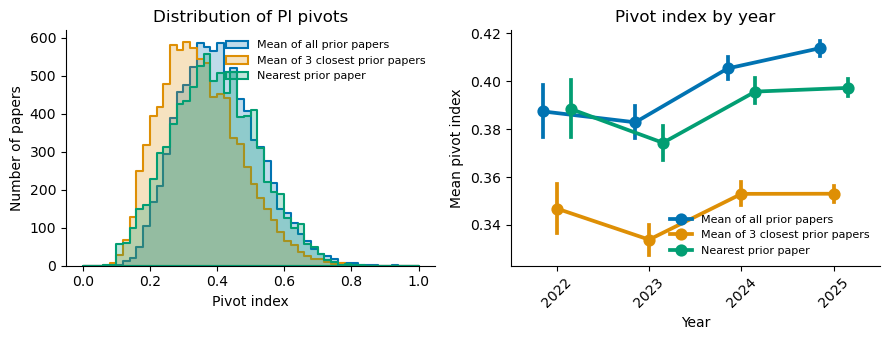

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

methods = {
    "pivot": "Mean of all prior papers",
    "pivot_k": "Mean of 3 closest prior papers",
    "pivot_nn": "Nearest prior paper",
}
colors = sns.color_palette("colorblind")[:3]
bins = np.linspace(0, 1, 51)  # same bins for every method so the bars line up

# simple distrbution across all papers
for (column, label), color in zip(methods.items(), colors):
    sns.histplot(pi_pivot[column], bins=bins, ax=axs[0], color=color, alpha=0.25, element="step", linewidth=1.5, label=label)
axs[0].set(xlabel="Pivot index", ylabel="Number of papers", title="Distribution of PI pivots")
axs[0].legend(fontsize=8, frameon=False)

# through years
pi_long = pi_pivot.melt(id_vars="year", value_vars=list(methods), var_name="method", value_name="value")
pi_long["method"] = pi_long["method"].map(methods)

sns.pointplot(
    data=pi_long, x="year", y="value", hue="method", hue_order=list(methods.values()),
    palette=colors, dodge=0.3, ax=axs[1]
)
axs[1].set(xlabel="Year", ylabel="Mean pivot index", title="Pivot index by year")
axs[1].tick_params(axis="x", rotation=45)
axs[1].legend(fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

### Example from Levine

To check that the index behaves as expected, we look at the papers of one prolific PI with the lowest and highest pivots.

In [15]:
author = "~Sergey_Levine1"
example = pi_pivot[pi_pivot["author"] == author].sort_values("pivot")

pd.concat([example.head(3), example.tail(3)])[["year", "n_prior", "pivot", "title"]]

,year,n_prior,pivot,title
4891,2025,89,0.167757,Leveraging Skills from Unlabeled Prior Data fo...
383,2022,30,0.173959,Offline Meta-Reinforcement Learning with Onlin...
84,2022,30,0.178500,Should I Run Offline Reinforcement Learning or...
6686,2025,89,0.538227,Defining Deception in Decision Making
2544,2024,70,0.652605,Latent Conservative Objective Models for Offli...
130,2022,30,0.680967,Data-Driven Offline Optimization for Architect...


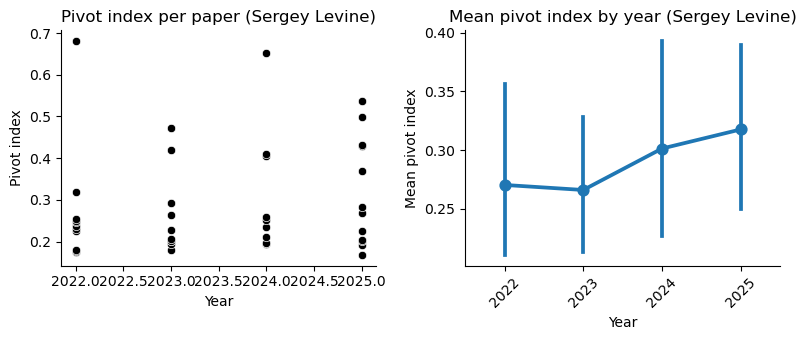

In [16]:
# Sergey Levine's pivot index across years (papers where he is the last author)
fig, axs = plt.subplots(1, 2, figsize=(8, 3.5))

# Pivot index of each paper
sns.scatterplot(data=example, x="year", y="pivot", ax=axs[0], color="black")
axs[0].set(xlabel="Year", ylabel="Pivot index", title="Pivot index per paper (Sergey Levine)")

# Mean pivot index per year, with 95% confidence intervals
sns.pointplot(data=example, x="year", y="pivot", ax=axs[1], estimator="mean")
axs[1].set(xlabel="Year", ylabel="Mean pivot index", title="Mean pivot index by year (Sergey Levine)")
axs[1].tick_params(axis="x", rotation=45)

sns.despine()
plt.tight_layout()
plt.show()

### Alternative histories for Levine

The pivot is noisy for prolific PIs: the same year mixes papers that continue earlier work and papers that move away from it. For the nearest prior paper, we also show which earlier paper it is, so we can check that the match makes sense.

In [17]:
# Nearest prior paper: lowest and highest pivots, with the earlier paper each one is closest to
example_nn = example.sort_values("pivot_nn").copy()
example_nn["nearest_prior_title"] = iclr2025v2.loc[example_nn["nearest_prior_idx"], "title"].to_numpy()

pd.concat([example_nn.head(3), example_nn.tail(3)])[["year", "n_prior", "pivot_nn", "title", "nearest_prior_title"]]

,year,n_prior,pivot_nn,title,nearest_prior_title
383,2022,30,0.126549,Offline Meta-Reinforcement Learning with Onlin...,Offline Meta-Reinforcement Learning with Advan...
1081,2023,52,0.128455,Confidence-Conditioned Value Functions for Off...,Offline Reinforcement Learning with Implicit Q...
2595,2024,70,0.133842,Advantage-Conditioned Diffusion: Offline RL vi...,Offline Reinforcement Learning with Implicit Q...
2544,2024,70,0.437771,Latent Conservative Objective Models for Offli...,Offline Model-Based Optimization via Normalize...
6686,2025,89,0.520653,Defining Deception in Decision Making,Adversarial Policies Beat Professional-Level G...
130,2022,30,0.539831,Data-Driven Offline Optimization for Architect...,Design-Bench: Benchmarks for Data-Driven Offli...


In [18]:
# How the three measures rank papers, for Levine and for all PI papers (Spearman correlation)
print("Sergey Levine")
print(example[["pivot", "pivot_k", "pivot_nn"]].corr(method="spearman").round(2))
print()

print("All PIs")
pi_pivot[["pivot", "pivot_k", "pivot_nn"]].corr(method="spearman").round(2)

Sergey Levine
          pivot  pivot_k  pivot_nn
pivot      1.00     0.79      0.74
pivot_k    0.79     1.00      0.93
pivot_nn   0.74     0.93      1.00

All PIs


,pivot,pivot_k,pivot_nn
pivot,1.00,0.86,0.75
pivot_k,0.86,1.00,0.92
pivot_nn,0.75,0.92,1.00


Since withdrawn and desk-rejected papers never received a final decision, we leave them out when looking at acceptance.

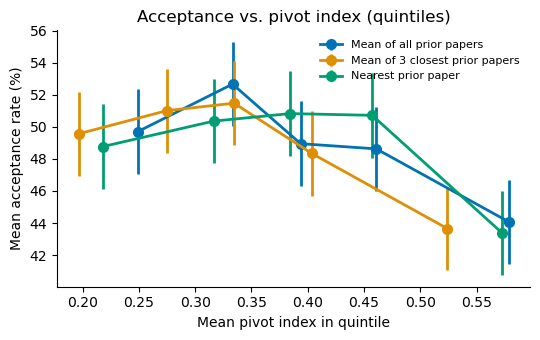

,method,pivot_bin,pivot_range,acceptance,n_papers
5,Mean of all prior papers,Q1,0.09 - 0.30,49.7,1386
6,Mean of all prior papers,Q2,0.30 - 0.36,52.7,1386
7,Mean of all prior papers,Q3,0.36 - 0.42,49.0,1385
8,Mean of all prior papers,Q4,0.42 - 0.50,48.6,1386
9,Mean of all prior papers,Q5,0.50 - 0.87,44.1,1386
0,Mean of 3 closest prior papers,Q1,0.07 - 0.24,49.6,1386
1,Mean of 3 closest prior papers,Q2,0.24 - 0.30,51.0,1386
2,Mean of 3 closest prior papers,Q3,0.30 - 0.37,51.5,1385
3,Mean of 3 closest prior papers,Q4,0.37 - 0.45,48.3,1386
4,Mean of 3 closest prior papers,Q5,0.45 - 0.79,43.7,1386


In [19]:
# filtering out 
decided = pi_pivot[~pi_pivot["decision"].isin(["Withdrawn", "Desk rejected"])].copy()
decided["accepted"] = decided["decision"].str.startswith("Accept")

# Divide into quintiles of each pivot index (each method gets its own quintiles)
quintile_labels = ["Q1", "Q2", "Q3", "Q4", "Q5"]
decided_long = []

for column, label in methods.items():
    rows = decided[["paper_id", "accepted"]].copy()
    rows["pivot_value"] = decided[column]
    rows["pivot_bin"] = pd.qcut(decided[column], q=5, labels=quintile_labels)
    rows["method"] = label
    decided_long.append(rows)

decided_long = pd.concat(decided_long, ignore_index=True)
decided_long["acceptance"] = decided_long["accepted"] * 100

# Mean pivot value and acceptance rate in each quintile, with a 95% confidence interval
binned = decided_long.groupby(["method", "pivot_bin"], observed=True).agg(
    pivot_mean=("pivot_value", "mean"),
    pivot_min=("pivot_value", "min"),
    pivot_max=("pivot_value", "max"),
    acceptance=("acceptance", "mean"),
    n_papers=("paper_id", "count"),
).reset_index()
binned["ci"] = 1.96 * np.sqrt(binned["acceptance"] * (100 - binned["acceptance"]) / binned["n_papers"])

fig, ax = plt.subplots(figsize=(5.5, 3.5))

# each point is one quintile, placed at its mean pivot value
for label, color in zip(methods.values(), colors):
    group = binned[binned["method"] == label]
    ax.errorbar(group["pivot_mean"], group["acceptance"], yerr=group["ci"],
                color=color, marker="o", markersize=7, linewidth=2, label=label)

ax.set(
    xlabel="Mean pivot index in quintile",
    ylabel="Mean acceptance rate (%)",
    title="Acceptance vs. pivot index (quintiles)"
)
ax.legend(fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

# pivot range of each quintile
binned["pivot_range"] = binned["pivot_min"].map("{:.2f}".format) + " - " + binned["pivot_max"].map("{:.2f}".format)
binned["method"] = pd.Categorical(binned["method"], categories=list(methods.values()))
binned.sort_values(["method", "pivot_bin"])[["method", "pivot_bin", "pivot_range", "acceptance", "n_papers"]].round(1)

# Vendi Score: How Specialized Is the PI?

The pivot index describes a *paper*: does it move away from the PI's past work? To describe the *PI*, we use the Vendi score (Friedman & Dieng, 2023) of their prior papers, the effective number of distinct directions in their history. Unlike the mean of the history, it does not assume that a PI works on a single topic: a PI with two separate topics scores about 2.

For a PI with prior papers $e_1, \dots, e_n$ (normalized embeddings):
1. **Window.** We take the $m = 5$ most recent prior papers, so every PI is scored on the same number of papers (the score can never exceed $n$).
2. **Similarity matrix.** $K_{ij} = e_i \cdot e_j$, the cosine similarity of every pair of papers; the diagonal is 1.
3. **Eigenvalues.** The eigenvalues $\lambda_1, \dots, \lambda_n$ of $K / n$ are non-negative and sum to 1. Each one is the share of the history that lies along one independent direction: one topic puts almost all the weight on a single eigenvalue, two separate topics split it between two.
4. **Entropy.** $H = -\sum_i \lambda_i \log \lambda_i$ measures how evenly that weight is spread.
5. **Vendi score.** $VS = e^{H}$, between 1 (all papers identical) and $n$ (all papers unrelated). A low score is a hedgehog, a high score a fox.

In [20]:
def vendi_score(embeddings):
    """Effective number of distinct directions among normalized embeddings (rows)."""
    n = len(embeddings)
    similarity = embeddings @ embeddings.T                  # step 2: n x n cosine similarities
    eigenvalues = np.linalg.eigvalsh(similarity / n)        # step 3: non-negative, sum to 1
    eigenvalues = eigenvalues[eigenvalues > 1e-12]          # drop numerical zeros (0 log 0 = 0)
    entropy = -(eigenvalues * np.log(eigenvalues)).sum()    # step 4
    return np.exp(entropy)                                  # step 5


# Toy example with 6 papers: the score counts the distinct topics
directions = np.eye(6)
close_topic = (directions[0] + directions[1]) / np.linalg.norm(directions[0] + directions[1])  # cosine 0.71 with topic A

toy_histories = {
    "6 copies of one topic": np.array([directions[0]] * 6),
    "3 papers on topic A, 3 on a close topic": np.array([directions[0]] * 3 + [close_topic] * 3),
    "3 papers on topic A, 3 on an unrelated topic B": np.array([directions[0]] * 3 + [directions[1]] * 3),
    "6 unrelated papers": directions,
}

for name, history in toy_histories.items():
    print(f"{name}: Vendi = {vendi_score(history):.2f}")

6 copies of one topic: Vendi = 1.00
3 papers on topic A, 3 on a close topic: Vendi = 1.52
3 papers on topic A, 3 on an unrelated topic B: Vendi = 2.00
6 unrelated papers: Vendi = 6.00


In [21]:
# Vendi score of each PI's history at the time of the paper, using the m most recent prior papers
m = 5

# each author's papers in time order (within a year, in dataset order)
author_history = {author: group.sort_values("year", kind="stable") for author, group in author_papers.groupby("author")}

vendi_records = []

for paper_idx, author, year in zip(pi_pivot["paper_idx"], pi_pivot["author"], pi_pivot["year"]):

    history = author_history[author]
    prior_indices = history.loc[history["year"] < year, "paper_idx"].to_numpy()   # step 1: years before t

    vendi_records.append({
        "paper_idx": paper_idx,
        "vendi": vendi_score(embedding_av[prior_indices[-m:]]),     # last m papers
        "vendi_full": vendi_score(embedding_av[prior_indices]),     # whole history
    })

pi_pivot = pi_pivot.merge(pd.DataFrame(vendi_records), on="paper_idx")
# How the Vendi score relates to the pivot measures and to history length (Spearman correlation)
pi_pivot[["vendi", "vendi_full", "pivot", "pivot_k", "pivot_nn", "n_prior"]].corr(method="spearman").round(2)

,vendi,vendi_full,pivot,pivot_k,pivot_nn,n_prior
vendi,1.00,0.42,0.24,0.15,0.16,0.15
vendi_full,0.42,1.00,0.06,-0.15,-0.08,0.93
pivot,0.24,0.06,1.00,0.86,0.75,-0.03
pivot_k,0.15,-0.15,0.86,1.00,0.92,-0.24
pivot_nn,0.16,-0.08,0.75,0.92,1.00,-0.16
n_prior,0.15,0.93,-0.03,-0.24,-0.16,1.00


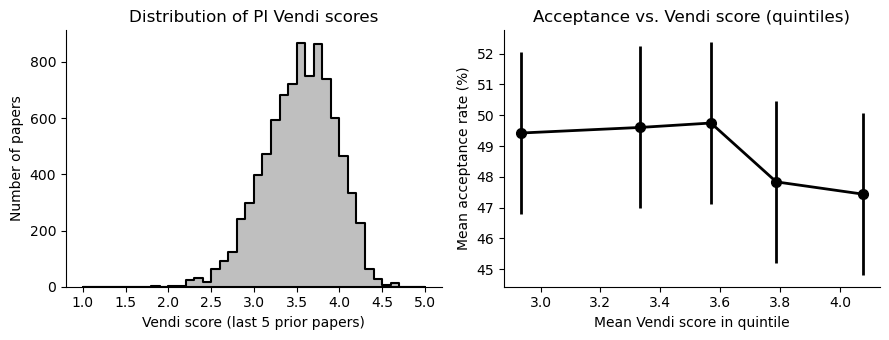

,vendi_bin,vendi_range,acceptance,n_papers
0,Q1,1.89 - 3.19,49.4,1386
1,Q2,3.19 - 3.46,49.6,1387
2,Q3,3.46 - 3.68,49.7,1385
3,Q4,3.68 - 3.90,47.8,1386
4,Q5,3.90 - 4.62,47.4,1385


In [22]:
# Acceptance by Vendi quintile (window of m = 5 papers)
decided = pi_pivot[~pi_pivot["decision"].isin(["Withdrawn", "Desk rejected"])].copy()
decided["acceptance"] = decided["decision"].str.startswith("Accept") * 100
decided["vendi_bin"] = pd.qcut(decided["vendi"], q=5, labels=quintile_labels)

binned_vendi = decided.groupby("vendi_bin", observed=True).agg(
    vendi_mean=("vendi", "mean"),
    vendi_min=("vendi", "min"),
    vendi_max=("vendi", "max"),
    acceptance=("acceptance", "mean"),
    n_papers=("paper_id", "count"),
).reset_index()
binned_vendi["ci"] = 1.96 * np.sqrt(binned_vendi["acceptance"] * (100 - binned_vendi["acceptance"]) / binned_vendi["n_papers"])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

sns.histplot(pi_pivot["vendi"], bins=np.linspace(1, m, 41), ax=axs[0], color="black", alpha=0.25, element="step", linewidth=1.5)
axs[0].set(xlabel=f"Vendi score (last {m} prior papers)", ylabel="Number of papers", title="Distribution of PI Vendi scores")

axs[1].errorbar(binned_vendi["vendi_mean"], binned_vendi["acceptance"], yerr=binned_vendi["ci"],
                color="black", marker="o", markersize=7, linewidth=2)
axs[1].set(xlabel="Mean Vendi score in quintile", ylabel="Mean acceptance rate (%)", title="Acceptance vs. Vendi score (quintiles)")

sns.despine()
plt.tight_layout()
plt.show()

binned_vendi["vendi_range"] = binned_vendi["vendi_min"].map("{:.2f}".format) + " - " + binned_vendi["vendi_max"].map("{:.2f}".format)
binned_vendi[["vendi_bin", "vendi_range", "acceptance", "n_papers"]].round(1)

# Within-PI Comparison

A PI's reputation, lab and field can affect both how much they pivot and how often they get accepted. To remove anything that is fixed about the PI, we compare each PI only with themselves:
- **Descriptive:** each paper's pivot and acceptance, relative to the PI's own averages.
- **Conditional logit:** a logistic regression grouped by PI. It only uses the contrast between a PI's accepted and rejected papers, so PIs whose papers were all accepted or all rejected drop out. We compare it with an ordinary logistic regression that pools all PIs (standard errors clustered by PI).

Both models control for year and $\log(1 + n_{prior})$. Each measure is standardized, so the coefficients are changes in the log-odds of acceptance per standard deviation. The last model includes the pivot and the Vendi score together, to separate how far the paper moves from how broad the PI is.

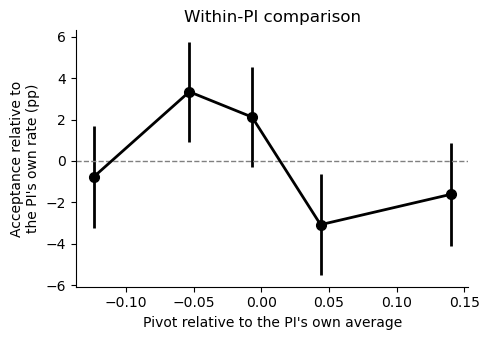

Papers: 6455, PIs: 1079


,pivot_bin,pivot_mean,acceptance,sd,n_papers,ci
0,Q1,-0.124,-0.766,45.192,1291,2.465
1,Q2,-0.053,3.345,44.097,1291,2.405
2,Q3,-0.007,2.120,44.526,1291,2.429
3,Q4,0.044,-3.081,44.655,1291,2.436
4,Q5,0.140,-1.618,45.418,1291,2.478


In [23]:
# Compare each PI with themselves: how far each paper's pivot is from that PI's own average pivot
decided = pi_pivot[~pi_pivot["decision"].isin(["Withdrawn", "Desk rejected"])].copy()
decided["accepted"] = decided["decision"].str.startswith("Accept")

within = decided[decided.groupby("author")["paper_id"].transform("count") >= 2].copy()
within["pivot_within"] = within["pivot"] - within.groupby("author")["pivot"].transform("mean")
within["acceptance_within"] = (within["accepted"] - within.groupby("author")["accepted"].transform("mean")) * 100
within["pivot_bin"] = pd.qcut(within["pivot_within"], q=5, labels=quintile_labels)

binned_within = within.groupby("pivot_bin", observed=True).agg(
    pivot_mean=("pivot_within", "mean"),
    acceptance=("acceptance_within", "mean"),
    sd=("acceptance_within", "std"),
    n_papers=("paper_id", "count"),
).reset_index()
binned_within["ci"] = 1.96 * binned_within["sd"] / np.sqrt(binned_within["n_papers"])

fig, ax = plt.subplots(figsize=(5, 3.5))

ax.errorbar(binned_within["pivot_mean"], binned_within["acceptance"], yerr=binned_within["ci"],
            color="black", marker="o", markersize=7, linewidth=2)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set(
    xlabel="Pivot relative to the PI's own average",
    ylabel="Acceptance relative to\nthe PI's own rate (pp)",
    title="Within-PI comparison"
)

sns.despine()
plt.tight_layout()
plt.show()

print(f"Papers: {len(within)}, PIs: {within['author'].nunique()}")
binned_within.round(3)

C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1122 observations for having no within-group variance
  warnings.warn(msg)


C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1122 observations for having no within-group variance
  warnings.warn(msg)


C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1122 observations for having no within-group variance
  warnings.warn(msg)


C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1122 observations for having no within-group variance
  warnings.warn(msg)


C:\Users\marti\anaconda3\Lib\site-packages\statsmodels\discrete\conditional_models.py:80: UserWarning: Dropped 714 groups and 1122 observations for having no within-group variance
  warnings.warn(msg)


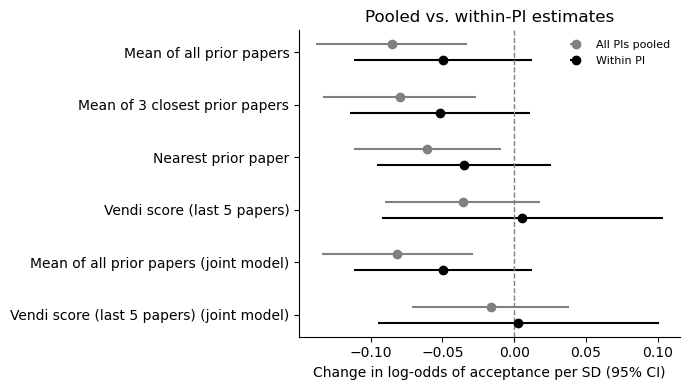

PIs with both accepted and rejected papers (used within PI): 839


,model,measure,comparison,log_odds_per_sd,ci_low,ci_high
0,Mean of all prior papers,Mean of all prior papers,All PIs pooled,-0.085,-0.138,-0.033
1,Mean of all prior papers,Mean of all prior papers,Within PI,-0.049,-0.111,0.012
2,Mean of 3 closest prior papers,Mean of 3 closest prior papers,All PIs pooled,-0.080,-0.133,-0.026
3,Mean of 3 closest prior papers,Mean of 3 closest prior papers,Within PI,-0.051,-0.114,0.011
4,Nearest prior paper,Nearest prior paper,All PIs pooled,-0.060,-0.111,-0.009
5,Nearest prior paper,Nearest prior paper,Within PI,-0.035,-0.096,0.026
6,Vendi score (last 5 papers),Vendi score (last 5 papers),All PIs pooled,-0.036,-0.090,0.018
7,Vendi score (last 5 papers),Vendi score (last 5 papers),Within PI,0.006,-0.092,0.103
8,Pivot + Vendi,Mean of all prior papers,All PIs pooled,-0.081,-0.134,-0.029
9,Pivot + Vendi,Vendi score (last 5 papers),All PIs pooled,-0.016,-0.071,0.038


In [ ]:
import statsmodels.api as sm
from statsmodels.discrete.conditional_models import ConditionalLogit

# Log-odds of acceptance per standard deviation of each measure, controlling for year and log(1 + n_prior)
measures = {**methods, "vendi": "Vendi score (last 5 papers)"}
specifications = {label: [column] for column, label in measures.items()}
specifications["Pivot + Vendi"] = ["pivot", "vendi"]

y = decided["accepted"].astype(int)
groups = pd.factorize(decided["author"])[0]
controls = pd.get_dummies(decided["year"], prefix="year", drop_first=True, dtype=float)
controls.insert(0, "log_n_prior", np.log1p(decided["n_prior"]))

model_rows = []

for specification, columns in specifications.items():

    X = controls.copy()
    for column in columns:
        X.insert(0, column, (decided[column] - decided[column].mean()) / decided[column].std())

    # all PIs pooled: compares different PIs with each other
    pooled = sm.Logit(y, sm.add_constant(X)).fit(disp=0, cov_type="cluster", cov_kwds={"groups": groups})

    # within PI: each PI is only compared with themselves
    within_fit = ConditionalLogit(y, X, groups=groups).fit(disp=0)

    for comparison, fit in [("All PIs pooled", pooled), ("Within PI", within_fit)]:
        for column in columns:
            low, high = fit.conf_int().loc[column]
            model_rows.append({
                "model": specification,
                "measure": measures[column],
                "comparison": comparison,
                "log_odds_per_sd": fit.params[column],
                "ci_low": low,
                "ci_high": high,
            })

models = pd.DataFrame(model_rows)
models["label"] = np.where(models["model"] == models["measure"], models["measure"], models["measure"] + " (joint model)")

fig, ax = plt.subplots(figsize=(7, 4))

labels = list(dict.fromkeys(models["label"]))
for offset, comparison, color in [(-0.15, "All PIs pooled", "gray"), (0.15, "Within PI", "black")]:
    rows = models[models["comparison"] == comparison]
    ax.errorbar(
        rows["log_odds_per_sd"], [labels.index(label) + offset for label in rows["label"]],
        xerr=[rows["log_odds_per_sd"] - rows["ci_low"], rows["ci_high"] - rows["log_odds_per_sd"]],
        fmt="o", color=color, markersize=6, label=comparison
    )

ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(range(len(labels)), labels)
ax.invert_yaxis()
ax.set(xlabel="Change in log-odds of acceptance per SD (95% CI)", title="Pooled vs. within-PI estimates")
ax.legend(fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

print(f"PIs with both accepted and rejected papers (used within PI): {(decided.groupby('author')['accepted'].nunique() == 2).sum()}")
models.drop(columns="label").round(3)

# Sanity Checks

The embeddings do not store paper ids, so we check that row `i` of the embeddings is row `i` of the dataframe: papers with the same abstract must have the same embedding.

In [20]:
assert len(embedding_av) == len(iclr2025v2)

duplicates = iclr2025v2[iclr2025v2["abstract"].duplicated(keep=False)].groupby("abstract").groups

for indices in duplicates.values():
    assert np.allclose(embedding_av[indices[0]], embedding_av[indices[1]])

print(f"Embeddings line up with the dataframe ({len(duplicates)} duplicated abstracts checked)")

Embeddings line up with the dataframe (20 duplicated abstracts checked)


The threshold of 5 prior papers is a choice. Below we recompute the acceptance rate by pivot quintile for other thresholds, and the gap in acceptance between the lowest (Q1) and highest (Q5) pivot quintiles.

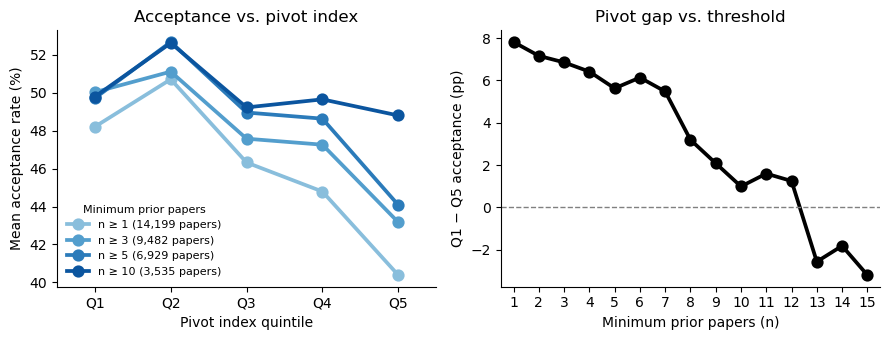

,threshold,gap,n_papers
0,1,7.816901,14199
1,2,7.161667,11486
2,3,6.852926,9482
3,4,6.417445,8022
4,5,5.627706,6929
5,6,6.135987,6030
6,7,5.477484,5341
7,8,3.194888,4692
8,9,2.085890,4074
9,10,0.990099,3535


In [21]:
quintiles = ["Q1", "Q2", "Q3", "Q4", "Q5"]
sensitivity = []
gaps = []

for n in range(1, 16):

    subset = author_papers[
        author_papers["is_last_author"]
        & (author_papers["n_prior"] >= n)
        & ~author_papers["decision"].isin(["Withdrawn", "Desk rejected"])
    ].copy()
    subset["accepted"] = subset["decision"].str.startswith("Accept")
    subset["pivot_bin"] = pd.qcut(subset["pivot"], q=5, labels=quintiles)

    rates = subset.groupby("pivot_bin", observed=True)["accepted"].mean() * 100

    gaps.append({"threshold": n, "gap": rates["Q1"] - rates["Q5"], "n_papers": len(subset)})

    if n in [1, 3, 5, 10]:
        for pivot_bin, rate in rates.items():
            sensitivity.append({
                "threshold": f"n ≥ {n} ({len(subset):,} papers)",
                "pivot_bin": pivot_bin,
                "mean_acceptance": rate,
            })

sensitivity = pd.DataFrame(sensitivity)
gaps = pd.DataFrame(gaps)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.5))

sns.pointplot(
    data=sensitivity,
    x="pivot_bin",
    y="mean_acceptance",
    hue="threshold",
    palette=sns.color_palette("Blues", 6)[2:],
    ax=axs[0]
)
axs[0].set(
    xlabel="Pivot index quintile",
    ylabel="Mean acceptance rate (%)",
    title="Acceptance vs. pivot index"
)
axs[0].legend(title="Minimum prior papers", fontsize=8, title_fontsize=8, frameon=False)

sns.pointplot(data=gaps, x="threshold", y="gap", ax=axs[1], color="black")
axs[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axs[1].set(
    xlabel="Minimum prior papers (n)",
    ylabel="Q1 − Q5 acceptance (pp)",
    title="Pivot gap vs. threshold"
)

sns.despine()
plt.tight_layout()
plt.show()

gaps

The window of the most recent prior papers is also a choice, and both the pivot and the Vendi score depend on how many papers they summarize. Below we recompute both on the $m$ most recent prior papers for $m = 5, 10, 15$, and on the full history. To separate the effect of the window from the effect of who is in the sample (shown by the threshold check above), we use the same papers for every window: PIs with at least 15 prior papers, so every window is full.

Papers in the window check: 2,111


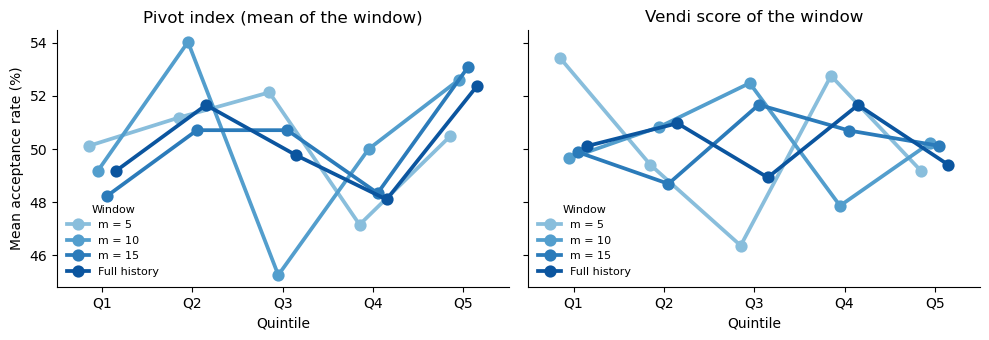

,window,measure,n_papers,Q1 - Q5 (pp),Spearman with n_prior
0,m = 5,pivot,2111,-0.36,0.03
1,m = 5,vendi,2111,4.26,-0.02
2,m = 10,pivot,2111,-3.43,0.01
3,m = 10,vendi,2111,-0.59,0.05
4,m = 15,pivot,2111,-4.85,-0.02
5,m = 15,vendi,2111,-0.24,0.12
6,Full history,pivot,2111,-3.20,-0.00
7,Full history,vendi,2111,0.71,0.78


In [22]:
windows = {"m = 5": 5, "m = 10": 10, "m = 15": 15, "Full history": None}
window_rates = []
window_summary = []

# same papers for every window: PIs with at least 15 prior papers
decided_pi = pi_pivot[~pi_pivot["decision"].isin(["Withdrawn", "Desk rejected"]) & (pi_pivot["n_prior"] >= 15)]

for window_label, window in windows.items():

    subset = decided_pi
    window_records = []

    for paper_idx, author, year, decision in zip(subset["paper_idx"], subset["author"], subset["year"], subset["decision"]):

        history = author_history[author]
        prior_indices = history.loc[history["year"] < year, "paper_idx"].to_numpy()
        n_prior = len(prior_indices)
        if window is not None:
            prior_indices = prior_indices[-window:]

        prior_mean = embedding_av[prior_indices].mean(axis=0)
        prior_mean = prior_mean / np.linalg.norm(prior_mean)

        window_records.append({
            "accepted": decision.startswith("Accept"),
            "n_prior": n_prior,
            "pivot": 1 - embedding_av[paper_idx] @ prior_mean,
            "vendi": vendi_score(embedding_av[prior_indices]),
        })

    window_df = pd.DataFrame(window_records)
    label = window_label

    for measure in ["pivot", "vendi"]:
        window_df["bin"] = pd.qcut(window_df[measure], q=5, labels=quintile_labels)
        rates = window_df.groupby("bin", observed=True)["accepted"].mean() * 100
        for bin_label, rate in rates.items():
            window_rates.append({"window": label, "measure": measure, "bin": bin_label, "acceptance": rate})
        window_summary.append({
            "window": window_label,
            "measure": measure,
            "n_papers": len(window_df),
            "Q1 - Q5 (pp)": rates["Q1"] - rates["Q5"],
            "Spearman with n_prior": window_df[measure].corr(window_df["n_prior"], method="spearman"),
        })

window_rates = pd.DataFrame(window_rates)

print(f"Papers in the window check: {len(decided_pi):,}")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)

for ax, measure, title in zip(axs, ["pivot", "vendi"], ["Pivot index (mean of the window)", "Vendi score of the window"]):
    sns.pointplot(
        data=window_rates[window_rates["measure"] == measure], x="bin", y="acceptance", hue="window",
        palette=sns.color_palette("Blues", 6)[2:], dodge=0.3, ax=ax
    )
    ax.set(xlabel="Quintile", ylabel="Mean acceptance rate (%)", title=title)
    ax.legend(title="Window", fontsize=8, title_fontsize=8, frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

pd.DataFrame(window_summary).round(2)

# Caveats
- **2021+ only, authors identified by OpenReview id.** Pivots start in 2022 because 2021 has no history. About 3% of author slots carry an email instead of a profile id, so the same person can appear under two ids, and a person with two profiles counts as two authors.
- **Resubmissions are detected with a cosine threshold of 0.90.** Some resubmissions with edited abstracts fall below it and remain.
- **History length matters.** The acceptance gap between low- and high-pivot papers shrinks for PIs with long histories; on the same papers, changing the window moves the gap by only a few points (within noise), so the shrinking gap mostly reflects who the experienced PIs are, not how many papers the measure summarizes.
- **Vendi window order.** Papers from the same year have no order, so when a window boundary falls inside a year, which of those papers enter the window is arbitrary.
- **Topic drift.** We do not control for topic or for field-wide shifts (e.g. the LLM era).